DAY 6: NUSSELT-NUMBER RESULTS
----------------------------------------------------------------------------------------------------
Ra=   500 | Nu_bottom=0.97603 | Nu_top=1.02395 | mismatch=4.79% | OK: mismatch within threshold
Ra=  1000 | Nu_bottom=0.97606 | Nu_top=1.02390 | mismatch=4.78% | OK: mismatch within threshold
Ra=  2500 | Nu_bottom=0.97613 | Nu_top=1.02379 | mismatch=4.77% | OK: mismatch within threshold
Ra=  5000 | Nu_bottom=0.97620 | Nu_top=1.02369 | mismatch=4.75% | OK: mismatch within threshold


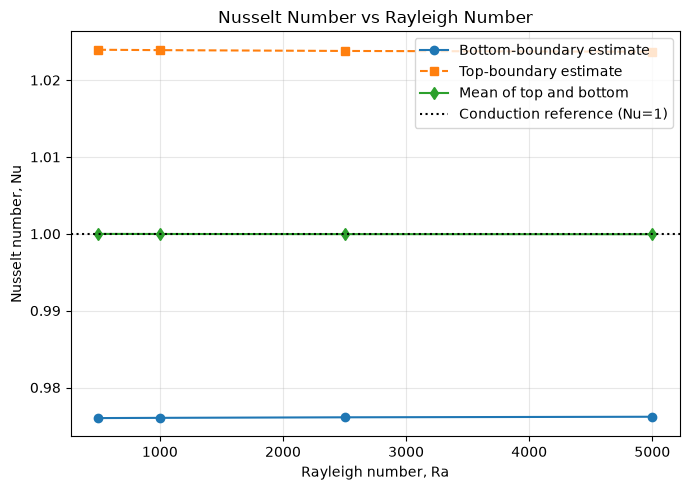

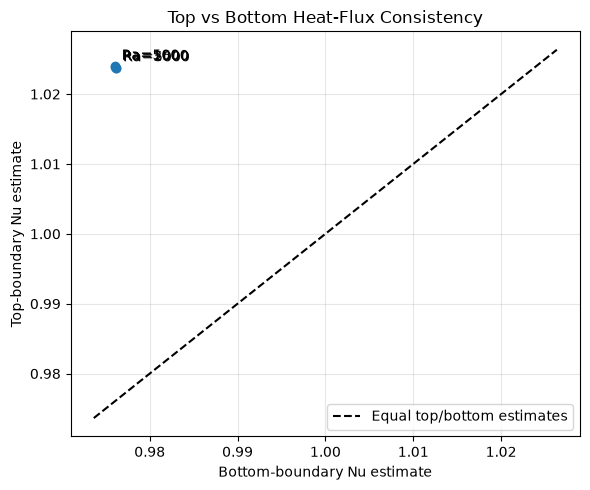


Saved summary: C:\Users\athil\OneDrive\Desktop\day6_results\day6_nusselt_summary.csv
Saved plots in: C:\Users\athil\OneDrive\Desktop\day6_results

Interpretation reminder:
- The conductive reference profile T=1-z gives Nu=1.
- A large top/bottom mismatch can indicate a transient field or numerical error.
- Do not claim steady-state heat transport unless time/grid convergence is checked.


In [1]:
"""
Day 6: Nusselt-number diagnostics and plots for the mantle-convection project.

This script combines:
- Person 2: calculate bottom/top Nusselt-number estimates from each Day-5 dataset.
- Person 3: save a CSV summary and create comparison plots.

Expected input files:
    day5_results/mantle_Ra_500.npz
    day5_results/mantle_Ra_1000.npz
    day5_results/mantle_Ra_2500.npz
    day5_results/mantle_Ra_5000.npz

Run this script from the same working directory as the day5_results folder,
or change DATA_DIR below.

Important:
These are boundary heat-flux estimates from the saved temperature field.
Unless the simulation is demonstrably at steady state, treat them as transient
diagnostics rather than final steady-state Nusselt numbers.
"""

from pathlib import Path
import csv

import numpy as np
import matplotlib.pyplot as plt


# ---------------------------------------------------------
# Settings: change these only if your folder is elsewhere
# ---------------------------------------------------------

DATA_DIR = Path("day5_results")
OUTPUT_DIR = Path("day6_results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

RA_VALUES = [500, 1000, 2500, 5000]

# If top and bottom estimates differ by more than this percentage,
# flag the result for further convergence checks.
FLUX_DIFFERENCE_WARNING_PERCENT = 10.0


# ---------------------------------------------------------
# Calculate Nusselt-number estimates for one simulation
# ---------------------------------------------------------

def calculate_nusselt(file_path):
    """Load one Day-5 dataset and estimate top/bottom Nusselt numbers."""

    data = np.load(file_path)

    T = data["T"]
    z = data["z"]

    # Uniform vertical grid spacing
    dz = z[1] - z[0]

    # Ignore the two sidewall corner points when averaging heat flux.
    # Bottom derivative: (T at first interior row - T at bottom) / dz
    bottom_gradient = (T[1, 1:-1] - T[0, 1:-1]) / dz

    # Top derivative: (T at top - T at row immediately below) / dz
    top_gradient = (T[-1, 1:-1] - T[-2, 1:-1]) / dz

    # With z increasing upward and T(bottom)=1, T(top)=0:
    # conductive reference T=1-z gives Nu=1 at both boundaries.
    nu_bottom = -float(np.mean(bottom_gradient))
    nu_top = -float(np.mean(top_gradient))

    # Relative mismatch between top and bottom estimates.
    mean_abs_nu = 0.5 * (abs(nu_bottom) + abs(nu_top))
    if mean_abs_nu > 1e-12:
        mismatch_percent = (
            abs(nu_bottom - nu_top) / mean_abs_nu * 100.0
        )
    else:
        mismatch_percent = 0.0

    warning = mismatch_percent > FLUX_DIFFERENCE_WARNING_PERCENT

    # Pull saved metadata if present.
    ra = float(data["ra"]) if "ra" in data.files else float(
        file_path.stem.split("_")[-1]
    )
    final_time = float(data["time"]) if "time" in data.files else np.nan
    steps = int(data["steps"]) if "steps" in data.files else -1

    data.close()

    return {
        "Ra": ra,
        "grid": f"{T.shape[1]}x{T.shape[0]}",
        "final_time": final_time,
        "steps": steps,
        "Nu_bottom": nu_bottom,
        "Nu_top": nu_top,
        "Nu_average": 0.5 * (nu_bottom + nu_top),
        "flux_mismatch_percent": mismatch_percent,
        "check": "CHECK FLUX/CONVERGENCE" if warning else "OK: mismatch within threshold",
    }


# ---------------------------------------------------------
# Main: process all Rayleigh numbers
# ---------------------------------------------------------

def main():
    results = []

    print("DAY 6: NUSSELT-NUMBER RESULTS")
    print("-" * 100)

    for ra in RA_VALUES:
        file_path = DATA_DIR / f"mantle_Ra_{ra}.npz"

        if not file_path.exists():
            print(f"Missing file: {file_path}")
            print("Make sure you have run the Day-5 script and that DATA_DIR is correct.")
            continue

        result = calculate_nusselt(file_path)
        results.append(result)

        print(
            f"Ra={result['Ra']:6.0f} | "
            f"Nu_bottom={result['Nu_bottom']:.5f} | "
            f"Nu_top={result['Nu_top']:.5f} | "
            f"mismatch={result['flux_mismatch_percent']:.2f}% | "
            f"{result['check']}"
        )

    if not results:
        print("\nNo datasets were processed. Check DATA_DIR and the input filenames.")
        return

    # Sort results by Rayleigh number.
    results.sort(key=lambda row: row["Ra"])

    # Save CSV table.
    csv_path = OUTPUT_DIR / "day6_nusselt_summary.csv"
    fieldnames = [
        "Ra", "grid", "final_time", "steps",
        "Nu_bottom", "Nu_top", "Nu_average",
        "flux_mismatch_percent", "check"
    ]

    with open(csv_path, "w", newline="", encoding="utf-8") as f:
        writer = csv.DictWriter(f, fieldnames=fieldnames)
        writer.writeheader()
        writer.writerows(results)

    # ---------------- Plot 1: Nusselt number vs Ra ----------------
    ra = [row["Ra"] for row in results]
    nu_bottom = [row["Nu_bottom"] for row in results]
    nu_top = [row["Nu_top"] for row in results]
    nu_average = [row["Nu_average"] for row in results]

    plt.figure(figsize=(7, 5))
    plt.plot(ra, nu_bottom, "o-", label="Bottom-boundary estimate")
    plt.plot(ra, nu_top, "s--", label="Top-boundary estimate")
    plt.plot(ra, nu_average, "d-", label="Mean of top and bottom")
    plt.axhline(1.0, color="black", linestyle=":", label="Conduction reference (Nu=1)")
    plt.xlabel("Rayleigh number, Ra")
    plt.ylabel("Nusselt number, Nu")
    plt.title("Nusselt Number vs Rayleigh Number")
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "day6_nusselt_vs_Ra.png", dpi=180)
    plt.show()

    # ---------------- Plot 2: compare top and bottom flux ----------------
    plt.figure(figsize=(6, 5))
    plt.plot(nu_bottom, nu_top, "o")
    low = min(min(nu_bottom), min(nu_top), 1.0)
    high = max(max(nu_bottom), max(nu_top), 1.0)
    padding = 0.05 * max(high - low, 1e-6)
    plt.plot(
        [low - padding, high + padding],
        [low - padding, high + padding],
        "k--",
        label="Equal top/bottom estimates"
    )

    for row in results:
        plt.annotate(
            f"Ra={row['Ra']:g}",
            (row["Nu_bottom"], row["Nu_top"]),
            xytext=(5, 5),
            textcoords="offset points"
        )

    plt.xlabel("Bottom-boundary Nu estimate")
    plt.ylabel("Top-boundary Nu estimate")
    plt.title("Top vs Bottom Heat-Flux Consistency")
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "day6_top_vs_bottom_nusselt.png", dpi=180)
    plt.show()

    print(f"\nSaved summary: {csv_path.resolve()}")
    print(f"Saved plots in: {OUTPUT_DIR.resolve()}")
    print("\nInterpretation reminder:")
    print("- The conductive reference profile T=1-z gives Nu=1.")
    print("- A large top/bottom mismatch can indicate a transient field or numerical error.")
    print("- Do not claim steady-state heat transport unless time/grid convergence is checked.")


if __name__ == "__main__":
    main()